# Low-rank adaptation

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/2_models/05_low_rank_adaptation.ipynb) &nbsp; Guide note: [guide-foundation-models](https://www.matthewwnuk.com/guide-foundation-models.html#lora)

Full fine-tuning updates every weight. Low-rank adaptation freezes the pretrained weights and learns a
correction that is the product of two thin matrices. This notebook pretrains a small network, adapts it
to a new task both ways, and looks at why the cheap way works.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

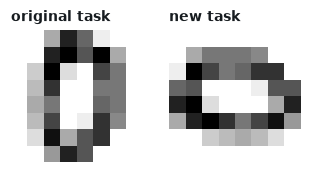

In [2]:
import copy, math, numpy as np, torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt
from guide_utils import data, style
style.use()
X, y = data.digits(); X, y = torch.tensor(X), torch.tensor(y)
idx = torch.randperm(len(y), generator=torch.Generator().manual_seed(0)); tr, te = idx[:1300], idx[1300:]
rotate = lambda x: torch.rot90(x.reshape(-1, 8, 8), 1, (1, 2)).reshape(-1, 64)        # the new task: the same digits turned a quarter turn
Xr = rotate(X)
fig, ax = plt.subplots(1, 2, figsize=(3.4, 1.9)); ax[0].imshow(X[0].reshape(8, 8), cmap="gray_r"); ax[0].set_title("original task", fontsize=9); ax[1].imshow(Xr[0].reshape(8, 8), cmap="gray_r"); ax[1].set_title("new task", fontsize=9)
for a in ax: style.bare(a)
plt.show()

def mlp(): return nn.Sequential(nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, 10))
def fit(params, forward, inputs, epochs=40, lr=1e-3):
    opt = torch.optim.Adam(params, lr)
    for ep in range(epochs):
        perm = tr[torch.randperm(len(tr))]
        for i in range(0, len(perm), 64):
            b = perm[i:i + 64]; loss = F.cross_entropy(forward(inputs[b]), y[b]); opt.zero_grad(); loss.backward(); opt.step()
@torch.no_grad()
def acc(forward, inputs): return (forward(inputs[te]).argmax(1) == y[te]).float().mean().item() * 100

## Pretrain, then fine-tune everything

In [3]:
torch.manual_seed(0); base = mlp(); fit(base.parameters(), base, X)
print(f"pretrained model:   original task {acc(base, X):.1f}%   new task {acc(base, Xr):.1f}%")
full = copy.deepcopy(base); fit(full.parameters(), full, Xr)
print(f"fully fine-tuned:   original task {acc(full, X):.1f}%   new task {acc(full, Xr):.1f}%   ({sum(p.numel() for p in full.parameters()):,} parameters trained)")

pretrained model:   original task 98.2%   new task 11.9%


fully fine-tuned:   original task 50.9%   new task 97.6%   (85,002 parameters trained)


Fine-tuning solves the new task and destroys the old one. That second number is catastrophic forgetting.

## How big was the change, really?

Take the difference between the fine-tuned and pretrained weights of the middle layer, a 256 x 256
matrix, and decompose it. If a few directions carry most of the change, a low-rank update can stand in
for it.

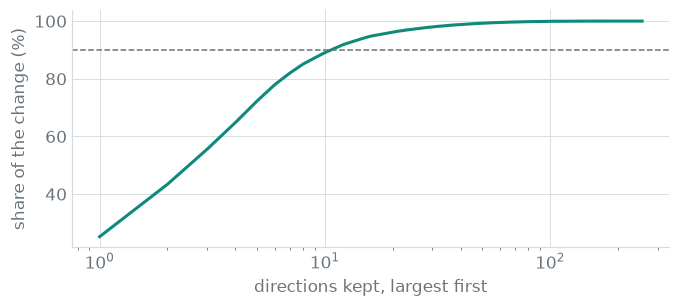

11 of 256 directions hold 90% of the change


In [4]:
sv = torch.linalg.svdvals((full[2].weight - base[2].weight).detach()); energy = (sv ** 2).cumsum(0) / (sv ** 2).sum(); k90 = int((energy < 0.9).sum()) + 1
plt.figure(figsize=(7, 2.8)); plt.plot(range(1, 257), energy * 100); plt.axhline(90, color=style.MUTED, ls="--", lw=1); plt.xscale("log"); plt.xlabel("directions kept, largest first"); plt.ylabel("share of the change (%)"); plt.show()
print(f"{k90} of 256 directions hold 90% of the change")

## The adapter

Each frozen weight matrix `W` gets a trainable correction `B @ A`, with `A` of shape (rank, inputs) and
`B` of shape (outputs, rank). `B` starts at zero, so training begins from exactly the pretrained model.

rank  1:  1,098 parameters ( 1.3% of the model)   new task 79.5%


rank  2:  2,196 parameters ( 2.6% of the model)   new task 92.8%


rank  4:  4,392 parameters ( 5.2% of the model)   new task 94.4%


rank  8:  8,784 parameters (10.3% of the model)   new task 97.4%


rank 16: 17,568 parameters (20.7% of the model)   new task 97.4%


rank 32: 35,136 parameters (41.3% of the model)   new task 98.2%


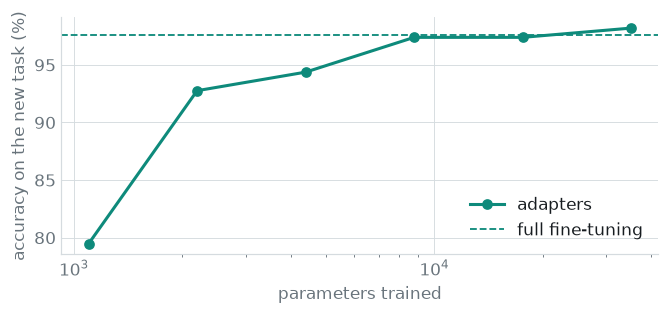

In [5]:
class LoRA(nn.Module):
    def __init__(self, base, rank):
        super().__init__(); self.base = copy.deepcopy(base)
        for p in self.base.parameters(): p.requires_grad_(False)
        layers = [self.base[0], self.base[2], self.base[4]]
        self.A = nn.ParameterList([nn.Parameter(torch.randn(rank, l.in_features) / math.sqrt(l.in_features)) for l in layers])
        self.B = nn.ParameterList([nn.Parameter(torch.zeros(l.out_features, rank)) for l in layers])
    def forward(self, x):
        for i, li in enumerate((0, 2, 4)):
            x = self.base[li](x) + x @ self.A[i].T @ self.B[i].T                 # frozen path + low-rank correction
            if li != 4: x = F.relu(x)
        return x

ranks = [1, 2, 4, 8, 16, 32]; accs, counts = [], []
for r in ranks:
    torch.manual_seed(0); m = LoRA(base, r); params = list(m.A) + list(m.B); fit(params, m, Xr, lr=3e-3); accs.append(acc(m, Xr)); counts.append(sum(p.numel() for p in params))
    print(f"rank {r:2d}: {counts[-1]:6,} parameters ({counts[-1] / sum(p.numel() for p in base.parameters()):5.1%} of the model)   new task {accs[-1]:.1f}%")
plt.figure(figsize=(7, 2.8)); plt.plot(counts, accs, marker="o", label="adapters"); plt.axhline(acc(full, Xr), color=style.TEAL, ls="--", lw=1.2, label="full fine-tuning")
plt.xscale("log"); plt.xlabel("parameters trained"); plt.ylabel("accuracy on the new task (%)"); plt.legend(); plt.show()

## What the adapter does not break

The base weights never changed. Remove the adapter and the original model is back, exactly.

In [6]:
m = LoRA(base, 8); fit(list(m.A) + list(m.B), m, Xr, lr=3e-3)
print(f"with the adapter:    new task {acc(m, Xr):.1f}%"); print(f"adapter removed:     original task {acc(m.base, X):.1f}%  (unchanged from {acc(base, X):.1f}%)")
merged = copy.deepcopy(base)
with torch.no_grad():
    for i, li in enumerate((0, 2, 4)): merged[li].weight += m.B[i] @ m.A[i]
print(f"adapter merged in:   new task {acc(merged, Xr):.1f}%  (the same model, no extra cost at run time)")

with the adapter:    new task 97.6%
adapter removed:     original task 98.2%  (unchanged from 98.2%)
adapter merged in:   new task 97.6%  (the same model, no extra cost at run time)


## Things to try

- Adapt only the middle layer. How much is lost?
- Initialise `B` randomly instead of at zero. What happens in the first few steps?
- Train two adapters, one per task, and switch between them at run time.